# Bài thực hành Buổi 1 - Bài 2 Trang 15-17
## Dữ liệu Titanic
**Sinh viên:** Ngô Thành Khôi - 6451071038

In [1]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")


Ngô Thành Khôi - 6451071038


### Câu 1: Nhập dữ liệu Titanic

In [2]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Đọc dữ liệu với kiểu dữ liệu số cần thiết
df = pd.read_csv("titanic.csv", dtype={"age": np.float64, "sibsp": np.int64, "parch": np.int64})
print("5 dòng đầu:")
display(df.head(12))
print("\nThông tin DataFrame:")
df.info()
print("\nThống kê mô tả:")
display(df.describe(include="all"))


Ngô Thành Khôi - 6451071038
5 dòng đầu:


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"



Thông tin DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB

Thống kê mô tả:


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
count,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,295,1307,486,121.000000,745
unique,NaN,NaN,1307,2,NaN,NaN,NaN,929,NaN,186,3,27,NaN,369
top,NaN,NaN,"Connolly, Miss. Kate",male,NaN,NaN,NaN,CA. 2343,NaN,C23 C25 C27,S,13,NaN,"New York, NY"
freq,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,6,914,39,NaN,64
mean,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN
std,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN
25%,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN
50%,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN
75%,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN


### Câu 2: Tìm 5 thuộc tính có nhiều giá trị rỗng nhất

In [3]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Liệt kê số lượng và tỷ lệ phần trăm giá trị rỗng
missing_count = df.isna().sum().sort_values(ascending=False)
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
missing_table = pd.concat([missing_count, missing_percent], axis=1)
missing_table.columns = ["Số lượng rỗng", "Tỷ lệ rỗng (%)"]
display(missing_table.head(5).round(2))


Ngô Thành Khôi - 6451071038


,Số lượng rỗng,Tỷ lệ rỗng (%)
body,1188,90.76
cabin,1014,77.46
boat,823,62.87
home.dest,564,43.09
age,263,20.09


### Câu 3: Liên hệ giữa tuổi, giới tính và khả năng sống sót

Ngô Thành Khôi - 6451071038


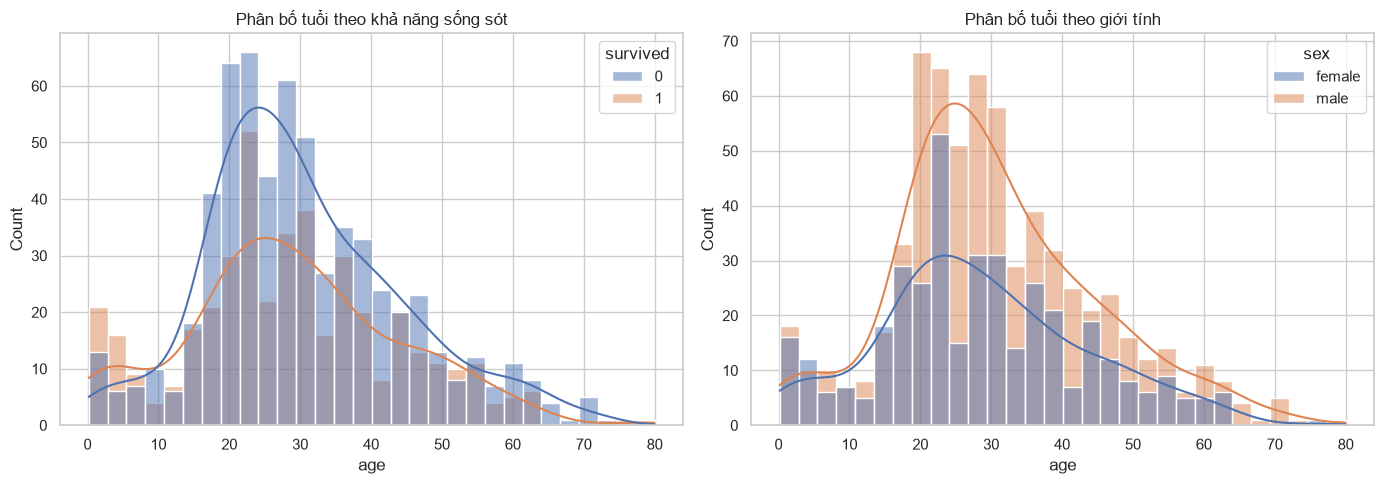

In [4]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Vẽ histogram/KDE theo tuổi, giới tính và trạng thái survived
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="age", hue="survived", kde=True, bins=30, ax=axes[0])
axes[0].set_title("Phân bố tuổi theo khả năng sống sót")
sns.histplot(data=df, x="age", hue="sex", kde=True, bins=30, ax=axes[1])
axes[1].set_title("Phân bố tuổi theo giới tính")
plt.tight_layout()
plt.show()


**Nhận xét:** Trẻ em và nhóm trẻ tuổi thường có tỷ lệ sống sót cao hơn; phụ nữ có xu hướng sống sót cao hơn nam trong các nhóm tuổi tương ứng.

### Câu 4: Liên hệ giữa cổng lên tàu, loại vé, giới tính và survived

Ngô Thành Khôi - 6451071038


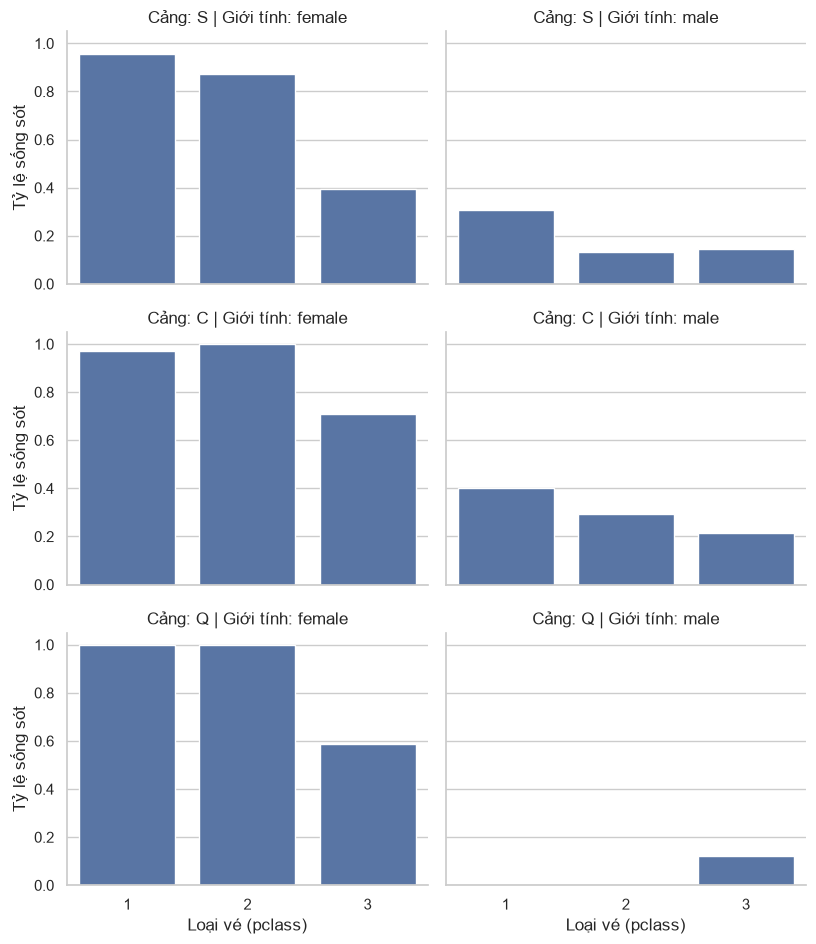

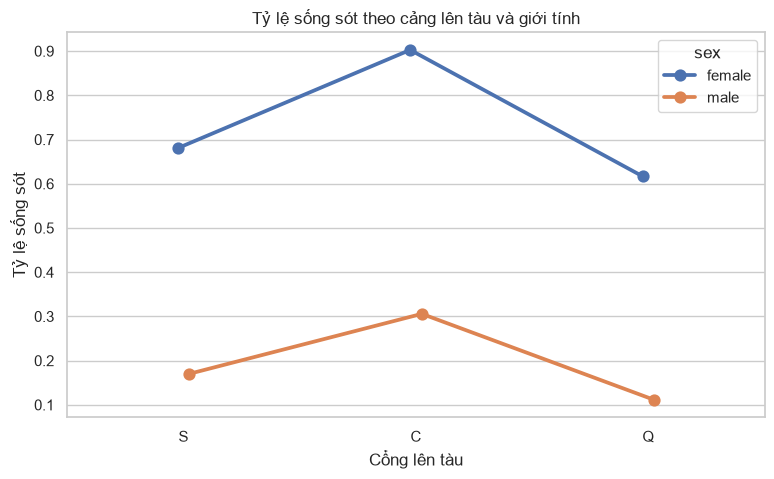

In [5]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Trực quan hóa FacetGrid và điểm trung bình tỷ lệ sống sót
g = sns.FacetGrid(df, col="sex", row="embarked", height=3.2, aspect=1.3)
g.map_dataframe(sns.barplot, x="pclass", y="survived", estimator=np.mean, errorbar=None)
g.set_axis_labels("Loại vé (pclass)", "Tỷ lệ sống sót")
g.set_titles(col_template="Giới tính: {col_name}", row_template="Cảng: {row_name}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.pointplot(data=df, x="embarked", y="survived", hue="sex", dodge=True, errorbar=None)
plt.title("Tỷ lệ sống sót theo cảng lên tàu và giới tính")
plt.xlabel("Cổng lên tàu")
plt.ylabel("Tỷ lệ sống sót")
plt.show()


**Nhận xét:** Phụ nữ nhìn chung có tỷ lệ sống sót cao hơn nam ở mọi cổng và loại vé. Cảng C cùng vé hạng nhất có xu hướng có tỷ lệ sống sót tốt hơn.

### Câu 5: Tạo relatives và not_alone; khảo sát survived

Ngô Thành Khôi - 6451071038


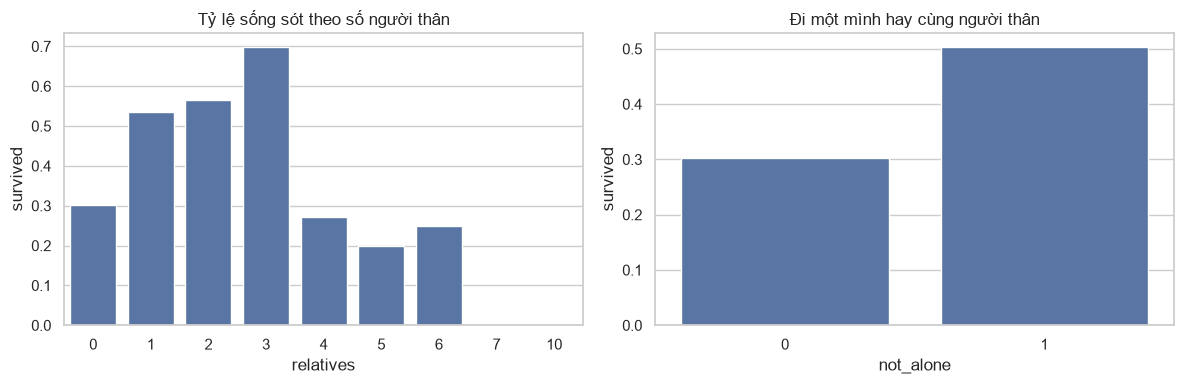

In [6]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Tạo thuộc tính relatives và not_alone
df["relatives"] = df["sibsp"] + df["parch"]
df["not_alone"] = np.where(df["relatives"] > 0, 1, 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x="relatives", y="survived", estimator=np.mean, errorbar=None, ax=axes[0])
axes[0].set_title("Tỷ lệ sống sót theo số người thân")
sns.barplot(data=df, x="not_alone", y="survived", estimator=np.mean, errorbar=None, ax=axes[1])
axes[1].set_title("Đi một mình hay cùng người thân")
plt.tight_layout()
plt.show()


**Nhận xét:** Hành khách đi cùng 1-3 người thân thường có tỷ lệ sống sót cao hơn hành khách đi một mình hoặc đi cùng rất đông người.

### Câu 6: Tiền xử lý dữ liệu thiếu và trích xuất deck

In [7]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Điền tuổi bằng giá trị ngẫu nhiên quanh mean/std
df["age"] = df["age"].fillna(-1)
age_mean = df.loc[df["age"] >= 0, "age"].mean()
age_std = df.loc[df["age"] >= 0, "age"].std()
age_low = int(max(0, age_mean - age_std))
age_high = int(max(age_low + 1, age_mean + age_std))
random_ages = np.random.randint(age_low, age_high, size=df["age"].eq(-1).sum())
df.loc[df["age"] == -1, "age"] = random_ages

# Điền embarked='S', fare=0
df["embarked"] = df["embarked"].fillna("S")
df["fare"] = df["fare"].fillna(0)

# Trích xuất deck từ cabin và ánh xạ sang số
df["deck"] = df["cabin"].map(lambda value: value[0] if isinstance(value, str) else "U")
deck_mapping = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df["deck"] = df["deck"].map(deck_mapping)

# Xóa các cột không còn cần thiết
df = df.drop(columns=["body", "boat", "home.dest", "cabin", "ticket"], errors="ignore")
print(df.isna().sum())
display(df.head())


Ngô Thành Khôi - 6451071038
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         0
embarked     0
relatives    0
not_alone    0
deck         1
dtype: int64


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,211.3375,S,0,0,2.0
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,151.5500,S,3,1,3.0
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,151.5500,S,3,1,3.0
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,151.5500,S,3,1,3.0
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,151.5500,S,3,1,3.0


### Câu 7: Chuyển đổi thuộc tính số và rời rạc hóa

In [8]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Chuyển fare sang int
df["fare"] = df["fare"].astype(int)

# Trích xuất title và ánh xạ sang số
df["title"] = df["name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
title_mapping = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4}
df["title"] = df["title"].map(title_mapping).fillna(5).astype(int)

# Mã hóa sex và embarked
df["sex"] = df["sex"].map({"male": 0, "female": 1}).astype(int)
df["embarked"] = df["embarked"].map({"S": 0, "C": 1, "Q": 2}).astype(int)

# Chia age thành 8 nhóm
df["age"] = pd.cut(
    df["age"],
    bins=[-np.inf, 11, 18, 22, 27, 33, 40, 66, np.inf],
    labels=False,
)
print("Phân bố nhóm tuổi:")
display(df["age"].value_counts().sort_index())

# Chia fare thành 6 nhóm
df["fare"] = pd.cut(
    df["fare"],
    bins=[-np.inf, 7.91, 14.454, 31, 99, 250, np.inf],
    labels=False,
)
print("Phân bố nhóm vé:")
display(df["fare"].value_counts().sort_index())


Ngô Thành Khôi - 6451071038
Phân bố nhóm tuổi:


age
0     90
1    139
2    174
3    218
4    225
5    208
6    246
7      9
Name: count, dtype: int64

Phân bố nhóm vé:


fare
0    361
1    312
2    325
3    227
4     67
5     17
Name: count, dtype: int64

### Câu 8: Tạo age_class và fare_per_person

In [9]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Tạo hai thuộc tính mới
df["age_class"] = df["age"] * df["pclass"]
df["fare_per_person"] = (df["fare"] / (df["relatives"] + 1)).astype(int)
print("10 dòng đầu sau khi tạo thuộc tính mới:")
display(df.head(10))


Ngô Thành Khôi - 6451071038
10 dòng đầu sau khi tạo thuộc tính mới:


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_class,fare_per_person
0,1,1,"Allen, Miss. Elisabeth Walton",1,4,0,0,4,0,0,0,2.0,2,4,4
1,1,1,"Allison, Master. Hudson Trevor",0,0,1,2,4,0,3,1,3.0,4,0,1
2,1,0,"Allison, Miss. Helen Loraine",1,0,1,2,4,0,3,1,3.0,2,0,1
3,1,0,"Allison, Mr. Hudson Joshua Creighton",0,4,1,2,4,0,3,1,3.0,1,4,1
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",1,3,1,2,4,0,3,1,3.0,3,3,1
5,1,1,"Anderson, Mr. Harry",0,6,0,0,2,0,0,0,5.0,1,6,2
6,1,1,"Andrews, Miss. Kornelia Theodosia",1,6,1,0,3,0,1,1,4.0,2,6,1
7,1,0,"Andrews, Mr. Thomas Jr",0,5,0,0,0,0,0,0,1.0,1,5,0
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",1,6,2,0,3,0,2,1,3.0,3,6,1
9,1,0,"Artagaveytia, Mr. Ramon",0,7,0,0,3,1,0,0,8.0,1,7,3
